# 04-认识T800的joint和link


## 1. 本课目标：T800 控制的花名册

本篇对应《具身智能机器人实战》第 04 节，课件标题为《认识 T800 的连杆和关节》，副标题是“T800 控制的花名册”。上一节已经加载机器人，本节关注如何把身体部位与模型中的具体对象对应起来。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/04_认识T800的joint和link.pptx` 全部 3 页：第 1 页为主题，第 2 页为教学图，第 3 页为品牌结束页。

课件以“抬起右胳膊”为例说明名称与编号之间的关系，没有展示代码或完整关节列表。下文先整理原课内容，再用上一节核对的官方模型补充一个名称查询示例。未转录配套视频，也未读取网盘中的 `code.zip`。


## 2. 从“右肩关节”找到计算机使用的对象

课件把同一个需求分成了人的表达与计算机处理两个层面：

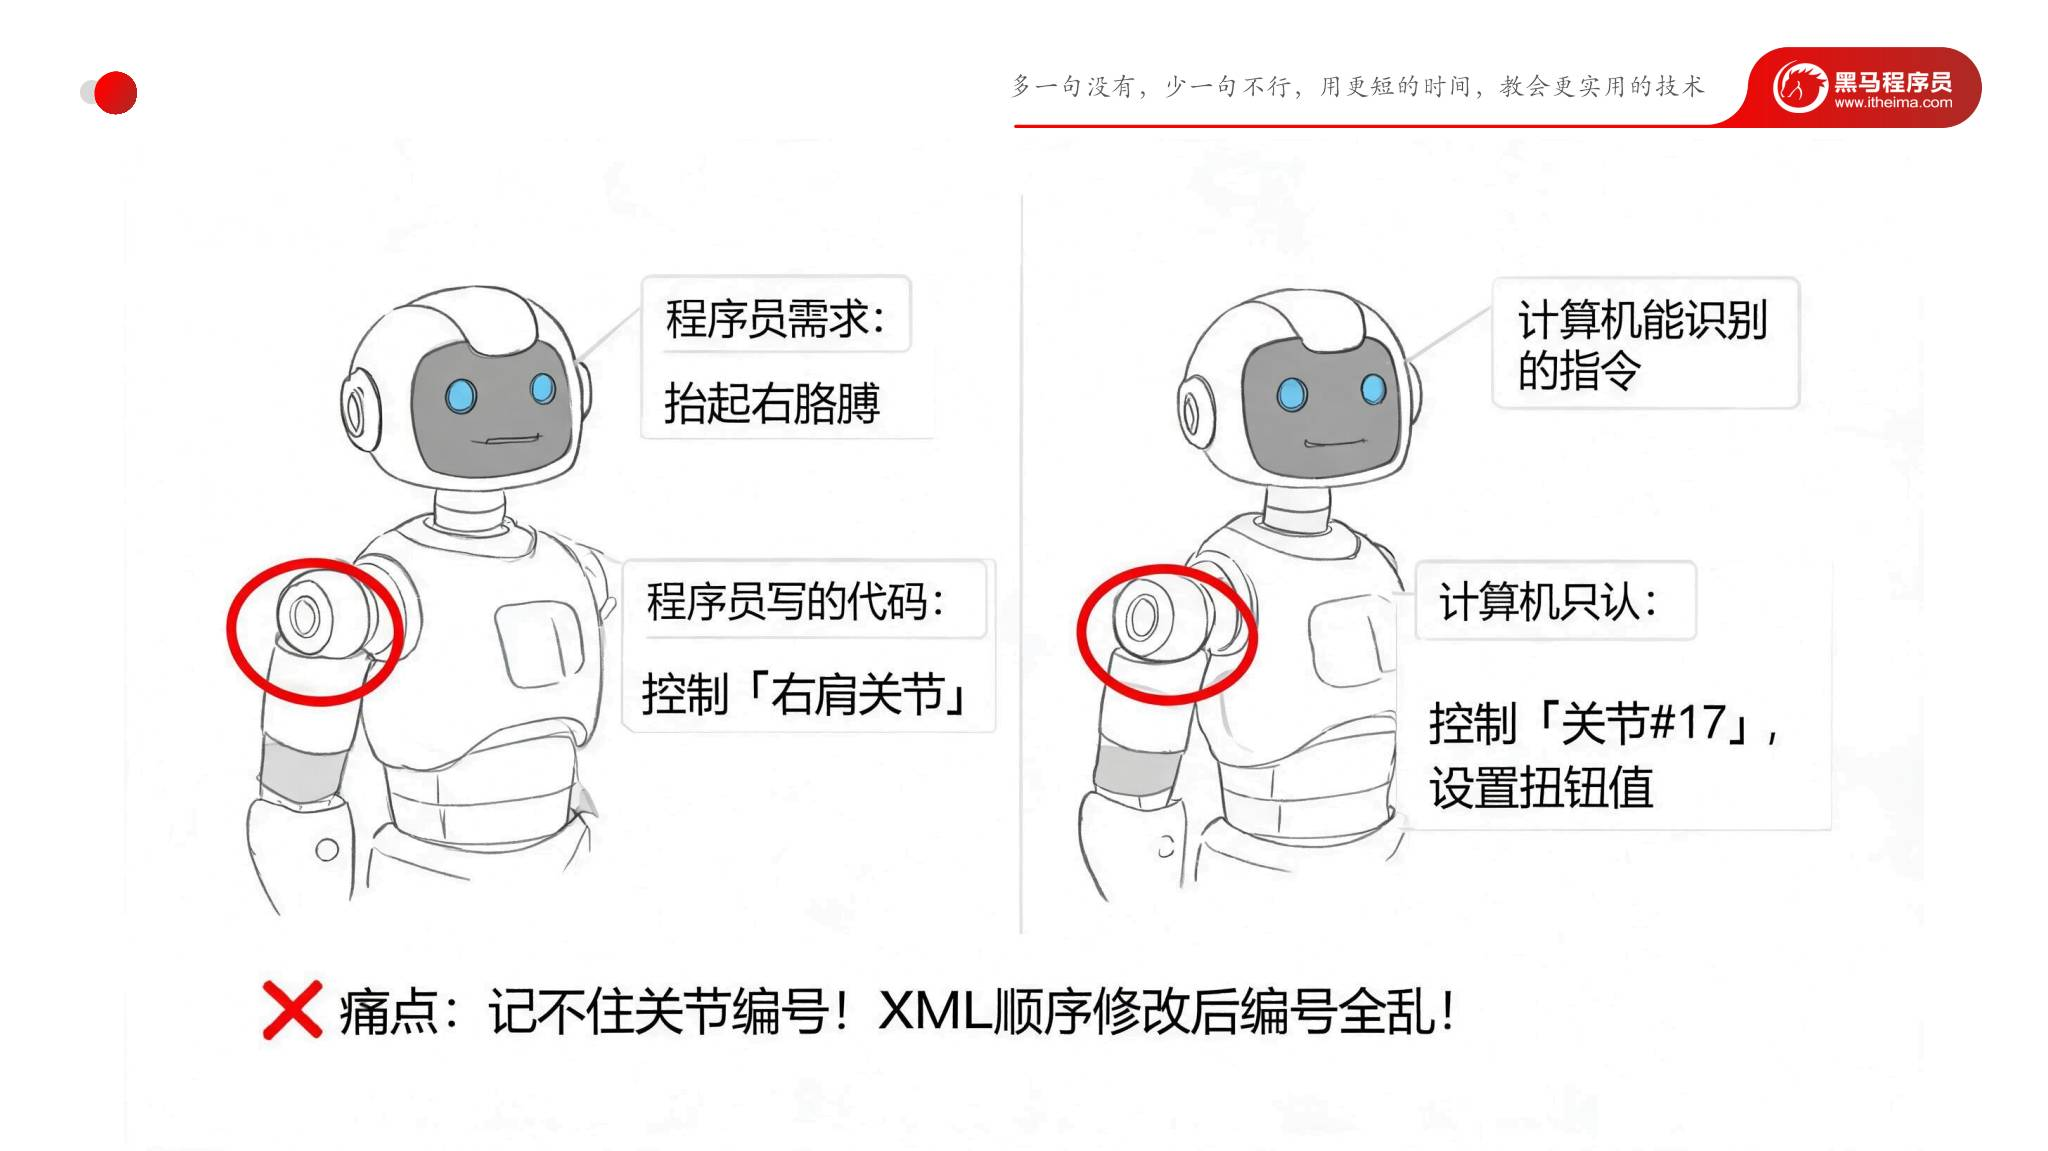

*原课件第 2 页：程序员说“右肩关节”，计算机按具体关节编号处理；底部指出记不住编号、XML 顺序变化会打乱编号的痛点。*

| 层面 | 课件示例 | 需要建立的对应关系 |
|---|---|---|
| 动作需求 | 抬起右胳膊 | 先确定涉及哪个身体部位 |
| 程序中的语义 | 控制“右肩关节” | 用能表达部位含义的名称描述目标 |
| 底层对象与输入 | 控制“关节 #17”，设置扭矩值 | 找到模型中的具体对象，再确定输入如何对应 |

这里的难点是：开发者容易理解“右肩”，却不容易记住所有关节编号。如果代码里到处写固定数字，就很难判断操作的是哪个部位；修改 XML 中的对象顺序并重新加载后，原来的数字还可能指向另一个关节。

> 课件中的“关节 #17”用于说明编号问题，不能直接当成 T800 右肩的固定编号。

因此，这份“花名册”需要把**部位含义、模型名称与当前模型中的编号**连起来。查名称时仍要确认具体运动轴：“右肩”是身体部位，而一个肩部可以包含多个关节对象。


## 3. 工程补充：按名称查询 joint 和 link

以下是为理解课件痛点补充的操作，使用第 03 篇同一官方仓库版本 `335c60e88772c26c7852d0abd6b3c7439037dd8f`，不是原课件中的代码。

### 3.1 在模型中分清两类对象

在这个 T800 的 MJCF 模型中，连杆由 `<body>` 描述，关节由其内部的 `<joint>` 描述。关节规定该 body 相对于父 body 可以怎样运动；body 的嵌套关系形成机器人的结构树。

例如，在 `assets/resource/robot/t800/xml/serial_links.xml` 中，右肩俯仰 body 名为 `LINK_SHOULDER_PITCH_R`，其内部的 joint 名为 `J18_SHOULDER_PITCH_R`，父 body 是躯干部件 `LINK_WAIST_YAW`。

`SHOULDER` 表示肩部，`PITCH、ROLL、YAW` 分别表示俯仰、横滚、偏航，`R/L` 表示机器人的右侧/左侧。具体正方向仍以 XML 的 `axis` 为准；名字中的 `J18` 是名称的一部分，不能直接当成 MuJoCo 的 joint ID。

### 3.2 打印名称与编号，再查找目标

沿用第 03 篇已经准备好的 `t800-load` 练习目录、官方模型和 `.venv`，新建 `inspect_t800.py`。脚本先打印当前模型的关节清单，再查询右肩俯仰关节及其所属 body：

```python
import argparse
from pathlib import Path

import mujoco

parser = argparse.ArgumentParser(description="核对 T800 关节与连杆名称")
parser.add_argument(
    "--model", type=Path,
    default=Path(__file__).resolve().parent
    / "engineai_robotics_native_sdk/assets/resource/t800.xml",
)
args = parser.parse_args()
model = mujoco.MjModel.from_xml_path(str(args.model.expanduser().resolve()))

for joint_id in range(model.njnt):
    joint_name = mujoco.mj_id2name(
        model, mujoco.mjtObj.mjOBJ_JOINT, joint_id
    )
    body_id = int(model.jnt_bodyid[joint_id])
    print(joint_id, joint_name or "<未命名>", model.body(body_id).name)

target_name = "J18_SHOULDER_PITCH_R"
joint_id = mujoco.mj_name2id(
    model, mujoco.mjtObj.mjOBJ_JOINT, target_name
)
if joint_id == -1:
    raise ValueError(f"当前模型没有关节：{target_name}")

body_id = int(model.jnt_bodyid[joint_id])
parent_id = int(model.body_parentid[body_id])
print(f"target: joint_id={joint_id}, body_id={body_id}")
print(f"body={model.body(body_id).name}, parent={model.body(parent_id).name}")
```

`mj_id2name()` 将当前对象编号转换成名称；`mj_name2id()` 按指定对象类型查名称，找不到时返回 `-1`，所以要先检查再作为数组下标使用。`jnt_bodyid` 给出关节所属 body 的 ID，`body_parentid` 给出父 body 的 ID。

在 `t800-load` 目录的 PowerShell 中执行：

```powershell
.\.venv\Scripts\python.exe inspect_t800.py
```

使用其他位置的模型时，显式指定保留完整资源目录的场景入口：

```powershell
.\.venv\Scripts\python.exe inspect_t800.py --model "D:\你的模型目录\assets\resource\t800.xml"
```

把示例路径替换成实际路径。本篇在 MuJoCo 3.4.0 与上述官方模型提交上实际运行脚本，目标查询结果为：

| 对象 | 名称 | 本次 ID |
|---|---|---:|
| 右肩俯仰关节 joint | `J18_SHOULDER_PITCH_R` | 19 |
| 该关节所属的 body | `LINK_SHOULDER_PITCH_R` | 23 |

脚本同时查到其父 body 名称为 `LINK_WAIST_YAW`。完整清单中的第 0 个关节显示为 `<未命名>`，对应模型里没有填写名称的浮动基座自由关节。

这也说明名称前缀 `J18`、joint ID `19` 和 body ID `23` 各有含义。更换模型、修改结构或顺序后，重新加载并按名称查询；若名称也改了，就更新代码中使用的名称。

**输入索引仍需另行核对：**joint ID、body ID 和 actuator（执行器）ID 属于不同对象类别。课件的“设置扭矩值”是概念示意，不能因此直接用 joint ID 给 `data.ctrl` 赋值，`ctrl` 按执行器排列。本节的脚本只查询模型结构。


## 4. 本课检查与补充参考

完成本节，应能根据关节名称定位当前模型里的对象，区分 joint 与连杆对应的 body，并解释为什么修改 XML 后需要重新核对编号。检查右肩时，要说明具体是俯仰、横滚还是偏航关节。

本篇补充脚本已实际读取官方 T800 模型，核对名称查询、关节所属 body 与父 body 的对应关系；没有推进仿真或验证抬臂动作。

补充内容的核对来源：

- [本篇版本的 T800 连杆与关节定义](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/robot/t800/xml/serial_links.xml)。
- [MuJoCo 3.4.0：按名称访问模型对象](https://mujoco.readthedocs.io/en/3.4.0/python.html#named-access)。
- [MuJoCo 3.4.0：mj_name2id 与 mj_id2name](https://mujoco.readthedocs.io/en/3.4.0/APIreference/APIfunctions.html#mj-name2id)。
- [MuJoCo 3.4.0：body 与 joint 的建模关系](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html#body-joint)。
